
# 06 - Data Leakage Experiment

## Objective

The objective of this notebook is to investigate potential data leakage in the Telco Customer Churn dataset.

Two potentially problematic features, Churn Score and CLTV, were excluded from the baseline model because their availability at prediction time was uncertain.

In this experiment, we will investigate how including these features affects model performance.

## Experiments

1. Baseline model without Churn Score and CLTV.
2. Model including Churn Score.
3. Model including both Churn Score and CLTV.

## Important Note

An increase in model performance does not automatically prove data leakage.

The timing, origin, and availability of each feature must also be considered.


In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")

print("Libraries imported successfully.")


Libraries imported successfully.



## 1. Load and Inspect Dataset

Load the original dataset and inspect the two potentially problematic features.

We will examine their data types, missing values, and descriptive statistics before including them in the experiments.


In [5]:

from pathlib import Path


file_path=Path.cwd().parent / "data" / "raw" / "Telco_customer_churn.xlsx"

df = pd.read_excel(
    file_path,
    sheet_name = "Telco_Churn"
)

suspicious_features = ["Churn Score", "CLTV"]

print("Dataset shape:", df.shape)

display(
    df[suspicious_features].describe().T
)

display(
    df[suspicious_features].isnull().sum()
)

display(
    df[suspicious_features].dtypes
)


Dataset shape: (7043, 33)


,count,mean,std,min,25%,50%,75%,max
Churn Score,7043.0,58.699418,21.525131,5.0,40.0,61.0,75.0,100.0
CLTV,7043.0,4400.295755,1183.057152,2003.0,3469.0,4527.0,5380.5,6500.0


Churn Score    0
CLTV           0
dtype: int64

Churn Score    int64
CLTV           int64
dtype: object


## 2. Define Feature Sets

Create three feature sets to investigate the impact of Churn Score and CLTV.

- Baseline: Excludes both suspicious features.
- Churn Score Experiment: Includes Churn Score only.
- Combined Experiment: Includes both Churn Score and CLTV.

All other features remain consistent across experiments.


In [7]:

y = df["Churn Value"]

excluded_columns = [
    "CustomerID",
    "Churn Label",
    "Churn Value",
    "Churn Reason",
    "Count",
    "Country",
    "State"
]

X_all = df.drop(columns=excluded_columns).copy()

X_all["Total Charges"] = pd.to_numeric(
    X_all["Total Charges"].astype(str).str.strip(),
    errors="coerce"
)

X_baseline = X_all.drop(columns=["Churn Score", "CLTV"])

X_churn_score = X_all.drop(columns=["CLTV"])

X_combined = X_all.copy()

print("Baseline:", X_baseline.shape)
print("Churn Score:", X_churn_score.shape)
print("Combined:", X_combined.shape)


Baseline: (7043, 24)
Churn Score: (7043, 25)
Combined: (7043, 26)


In [8]:

train_indices, test_indices = train_test_split(
    df.index,
    test_size=0.20,
    random_state=42,
    stratify=y
)

y_train = y.loc[train_indices]
y_test = y.loc[test_indices]

print("Training samples:", len(train_indices))
print("Testing samples:", len(test_indices))


Training samples: 5634
Testing samples: 1409


In [10]:

def create_model(X_train):
    numerical_features = X_train.select_dtypes(
        include=["number"]
    ).columns.tolist()

    categorical_features = X_train.select_dtypes(
        exclude=["number"]
    ).columns.tolist()

    numerical_pipeline = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])

    categorical_pipeline = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ])

    preprocessor = ColumnTransformer(transformers=[
        ("num", numerical_pipeline, numerical_features),
        ("cat", categorical_pipeline, categorical_features)
    ])

    model = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", RandomForestClassifier(
            n_estimators=200,
            random_state=42,
            class_weight="balanced",
            n_jobs=-1
        ))
    ])

    return model


In [11]:

feature_sets = {
    "Baseline": X_baseline,
    "Churn Score": X_churn_score,
    "Churn Score + CLTV": X_combined
}

experiment_results = []

trained_models = {}

for experiment_name, X in feature_sets.items():

    X_train = X.loc[train_indices]
    X_test = X.loc[test_indices]

    model = create_model(X_train)

    model.fit(X_train, y_train)

    probabilities = model.predict_proba(X_test)[:, 1]

    predictions = (
        probabilities >= 0.45
    ).astype(int)

    experiment_results.append({
        "Experiment": experiment_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions),
        "Recall": recall_score(y_test, predictions),
        "F1-Score": f1_score(y_test, predictions),
        "ROC-AUC": roc_auc_score(y_test, probabilities)
    })

    trained_models[experiment_name] = model

    print(f"{experiment_name} completed.")

experiment_df = pd.DataFrame(experiment_results)

experiment_df.round(4)


Baseline completed.
Churn Score completed.
Churn Score + CLTV completed.


,Experiment,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Baseline,0.7729,0.5551,0.7273,0.6296,0.8438
1,Churn Score,0.9106,0.7938,0.8957,0.8417,0.9531
2,Churn Score + CLTV,0.9127,0.8024,0.8904,0.8441,0.9521



## 3. Experiment Results

Compare the performance of the three models to investigate how including Churn Score and CLTV affects predictive performance.

All experiments use the same train-test split, preprocessing strategy, Random Forest configuration, and decision threshold.


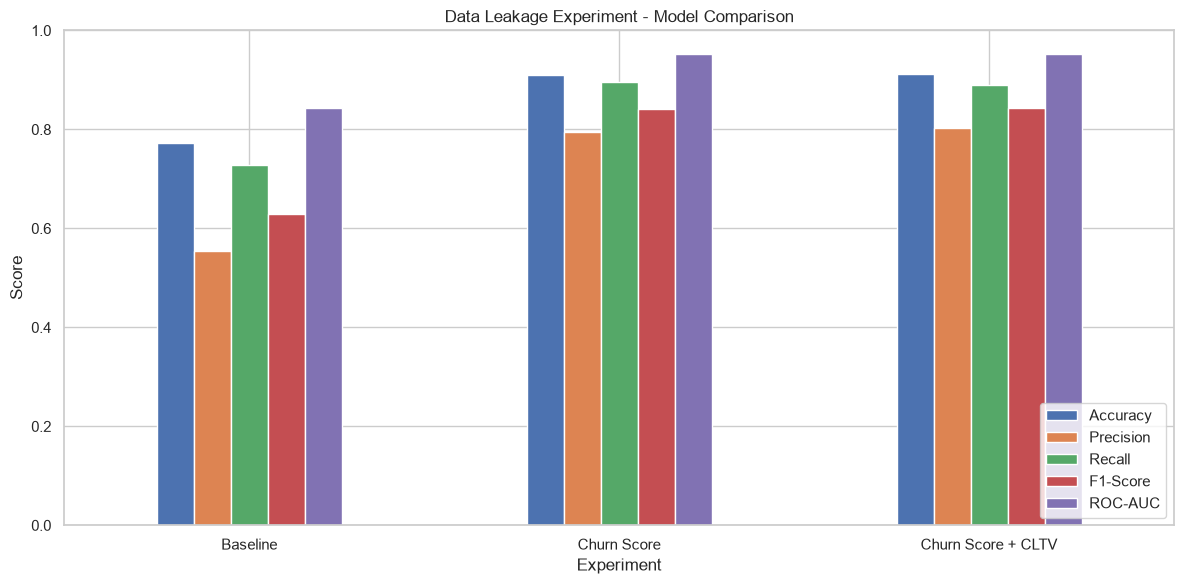

In [12]:

metrics_to_compare = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-Score",
    "ROC-AUC"
]

experiment_df.set_index("Experiment")[metrics_to_compare].plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Data Leakage Experiment - Model Comparison")
plt.ylabel("Score")
plt.xlabel("Experiment")
plt.xticks(rotation=0)
plt.ylim(0, 1)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()



## 4. Conclusion

This experiment investigates the impact of including Churn Score and CLTV in the customer churn prediction model.

An improvement in predictive performance does not automatically indicate data leakage.

To determine whether these features introduce leakage, their origin, calculation methodology, and availability at the actual prediction time must be investigated.

Features that are unavailable at prediction time should not be used in a production model, even if they improve offline evaluation metrics.

The baseline model remains the primary reference because it excludes features whose prediction-time availability is uncertain.
